##Logistic regression with scikit-learn

**Initial reading:**

Reading and understanding the scikit-learn examples on logistic regression is a good way to get started. There are no fewer than 5 examples given in the [logistic regression section](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) of the scikit-learn User manual. Feel free to look at all five but for sure look at the first two: L1 Penalty and Sparsity in Logistic Regression and Regularization path of L1- Logistic Regression. You will see that by default scikit-learn uses an L2 penalty (like in ridge regression) but it is also possible to use an
L1 penalty (like in lasso regression). Built-in cross-validation support for choosing the ‘right’ value for the complexity parameter is also available via the [LogisticRegressionCV class](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html).

**Diagnosing breast cancer:**

Go to the Breast Cancer Wisconsin (Diagnostic) data set [webpage](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic)). If you click on the ‘Data Folder’ link near the top of the page, then you will be able to get the data. It is the file [breast-cancer-wisconsin.data](https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/). You can either upload this to the session storage for your colab notebook (but it will be lost each time your session times out, although you can add `!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data` to your script to automatically download to session storage each time it runs - as done below) or you can mount a google drive folder and store the file there.

To save you hassle of working out how to get this data into a Python program is some code to read this data in, and then remove any datapoints containing missing values:

In [ ]:
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data

import numpy as np
from sklearn.linear_model import LogisticRegression

data = np.genfromtxt('breast-cancer-wisconsin.data',delimiter=',',missing_values='?')
data = data[~np.isnan(data).any(axis=1)]
X = data[:,1:-1] # ignore first column and omit class variable at the end
y = data[:,-1]

**To do:**

Now use logistic regression to build a model to predict either malignant or benign. In fact, I would like you to build a number of logistic regression models where you *vary the size of the training data* and where you *vary the complexity parameter setting*. In all cases use whatever data you have excluded from training as a test set, and compute the score.

Check that training on more data increases predictive accuracy and compare the performance of different complexity parameter settings on smaller training sets.

##Logistic Regression in PyTorch

Below is a straightforward re-implementation of logistic regression in PyTorch. Nearly all of this should now be very familiar to you. We put our logistic regression model in a superclass of `torch.nn.Module`. The model itself consists of a linear layer mapping 9 input features to 1 output. This is then passed through a sigmoid layer so that the model outputs probability of one of the two classes. Since we are doing binary cross entropy loss, we use `torch.nn.BCELoss` as our loss function (note: the sigmoid is applied inside the model so we don't use the version of the loss function that combines sigmoid and BCE - but this would be a perfectly valid alternative). We train as normal and evaluate on the test set. But this time, we threshold the output probabilities to make our final hard class decisions and compute the percent correct.

**To do:**

Read and understand this code block. Run it. Print out the shapes of the tensors as they pass through the `logisticRegression` model (all tensors have a `shape` attribute). Make sure the shapes corresponds with your understanding of what each layer is doing. Try changing the training set size, number of training iterations and learning rate and see the effect.

epoch 0, loss 0.8117485642433167
epoch 30, loss 0.3679882884025574
epoch 60, loss 0.31597623229026794
epoch 90, loss 0.2882087230682373
Percent training set correctly classified: 93.25%
Percent test set correctly classified: 91.87%


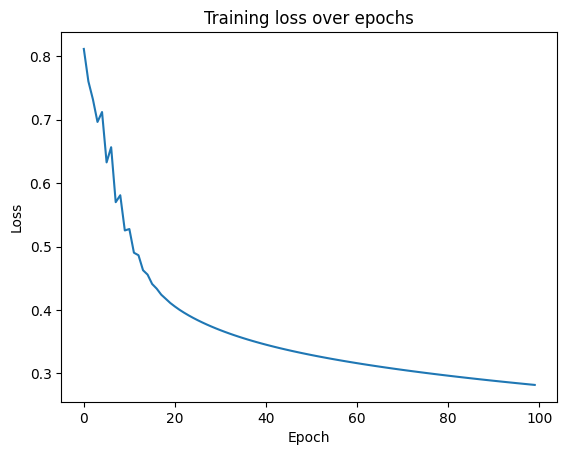

In [ ]:
import torch

class logisticRegression(torch.nn.Module):
    def __init__(self, inputSize):
        # Call superclass constructor
        super(logisticRegression, self).__init__()
        # Initialise components of model:
        # 1. Linear layer
        self.linear = torch.nn.Linear(inputSize, 1)
        # 2. Sigmoid layer
        self.sigmoid = torch.nn.Sigmoid()

    def forward(self, x):
        # Forward pass through the model:
        # 1. Apply linear layer to input
        y = self.linear(x)
        # 2. Apply sigmoid to output of linear layer
        y = self.sigmoid(y)
        return y

# Instantiate model logistic regression model 9 channel input
model = logisticRegression(9)
# Instantiate loss function (binary cross entropy loss - sigmoid applied inside model)
criterion = torch.nn.BCELoss()
# Setup optimiser
optim = torch.optim.SGD(model.parameters(), lr=0.1)

training_size = 400
epochs = 100

# Convert labels to binary 0/1 classes as expected by PyTorch
y_01 = np.array([0 if x==2 else 1 for x in data[:,-1]])

# Split train/test and convert to PyTorch tensors
X_train_tensor = torch.from_numpy(np.float32(X[:training_size]))
Y_train_tensor = torch.from_numpy(np.float32(y_01[:training_size])).unsqueeze(1)
X_test_tensor = torch.from_numpy(np.float32(X[training_size:]))
Y_test_tensor = torch.from_numpy(np.float32(y_01[training_size:])).unsqueeze(1)

losses = []

# Main training loop
for epoch in range(epochs):
    # Pass training data through model
    y_predict = model(X_train_tensor)
    # Compute BCE loss
    loss = criterion(y_predict,Y_train_tensor)
    # Backward pass and gradient step
    optim.zero_grad()
    loss.backward()
    optim.step()
    losses.append(loss.item())
    if not epoch % 30:
        # Print out the loss every 30 iterations
        print('epoch {}, loss {}'.format(epoch, loss.item()))

# Pass training set through model
y_predict = model(X_train_tensor)
# Threshold probabilities to binary classes
predictions = (y_predict>0.5).float()
# Compare predicted classes to labels
correct = (predictions == Y_train_tensor).float().sum()
print("Percent training set correctly classified: {:.2f}%".format(100*correct/training_size))

# Pass test set through model
y_predict = model(X_test_tensor)
# Threshold probabilities to binary classes
predictions = (y_predict>0.5).float()
# Compare predicted classes to labels
correct = (predictions == Y_test_tensor).float().sum()
print("Percent test set correctly classified: {:.2f}%".format(100*correct/X_test_tensor.shape[0]))

plt.plot(losses)
plt.title("Training loss over epochs")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

##Solutions

In [ ]:
def learn(training_size,c):
    trainy = y[:training_size]
    trainX = X[:training_size]

    testy = y[training_size:]
    testX = X[training_size:]

    reg = LogisticRegression(C=c,solver='liblinear')
    reg.fit(trainX,trainy)
    return reg.coef_, reg.score(testX,testy)


print('Number of datapoints is ',len(X))

# You could plot these out to get a better idea
for c in 0.01, 0.1, 1, 100:
    for i in range(50,600):
        print(i, c, learn(i,c)[1])

#learn(400,1)
#learn(220,0.1)

#learn(220,0.001)

#learn(150,100000)

#learn(150,0.000000001)


Number of datapoints is  683
50 0.01 0.7235387045813586
51 0.01 0.7120253164556962
52 0.01 0.6687797147385103
53 0.01 0.5714285714285714
54 0.01 0.5643879173290938
55 0.01 0.5652866242038217
56 0.01 0.4529505582137161
57 0.01 0.4488817891373802
58 0.01 0.448
59 0.01 0.44711538461538464
60 0.01 0.45264847512038525
61 0.01 0.4517684887459807
62 0.01 0.44605475040257647
63 0.01 0.45
64 0.01 0.40549273021001614
65 0.01 0.43527508090614886
66 0.01 0.42301458670988656
67 0.01 0.4172077922077922
68 0.01 0.432520325203252
69 0.01 0.44788273615635177
70 0.01 0.4453507340946166
71 0.01 0.4477124183006536
72 0.01 0.44680851063829785
73 0.01 0.42950819672131146
74 0.01 0.4433497536945813
75 0.01 0.46710526315789475
76 0.01 0.49093904448105435
77 0.01 0.49504950495049505
78 0.01 0.512396694214876
79 0.01 0.5198675496688742
80 0.01 0.5638474295190713
81 0.01 0.6013289036544851
82 0.01 0.6206322795341098
83 0.01 0.6183333333333333
84 0.01 0.6160267111853088
85 0.01 0.6137123745819398
86 0.01 0.609715

# Let's plot the learning curve:

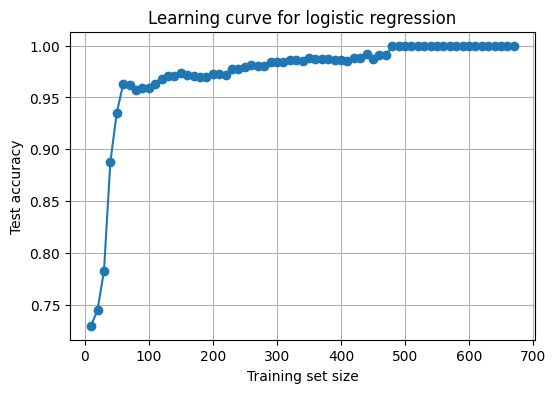

In [ ]:
import matplotlib.pyplot as plt

sizes = list(range(10, len(X)-10, 10))
scores = []

for s in sizes:
    _, score = learn(s, 1)
    scores.append(score)

plt.figure(figsize=(6,4))
plt.plot(sizes, scores, marker='o')
plt.xlabel("Training set size")
plt.ylabel("Test accuracy")
plt.title("Learning curve for logistic regression")
plt.grid(True)
plt.show()

# What a sigmoid function looks like:

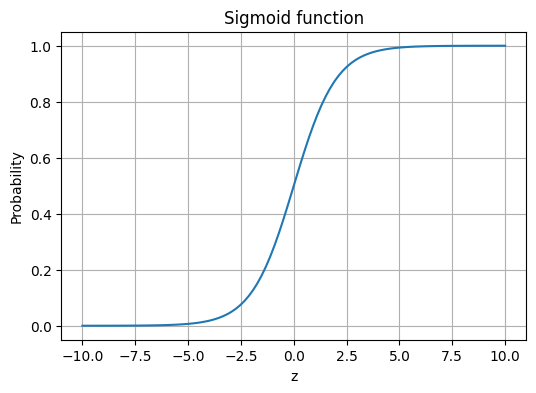

In [ ]:
x = np.linspace(-10,10,100)
sigmoid = 1/(1+np.exp(-x))

plt.figure(figsize=(6,4))
plt.plot(x, sigmoid)
plt.title("Sigmoid function")
plt.xlabel("z")
plt.ylabel("Probability")
plt.grid(True)
plt.show()

# Feature importance (coefficient values):

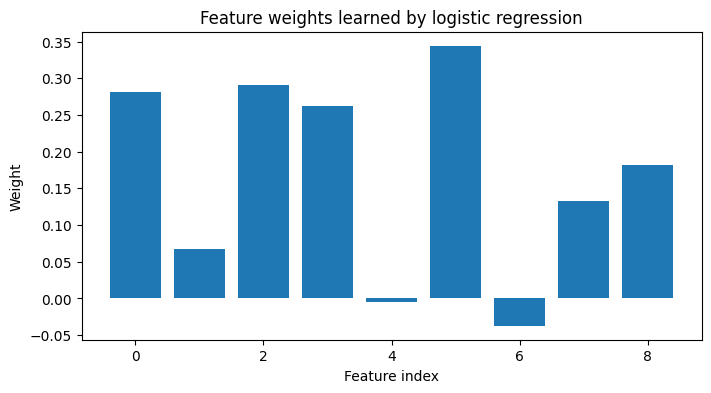

In [ ]:
coef, score = learn(400,1)

plt.figure(figsize=(8,4))
plt.bar(range(len(coef[0])), coef[0])
plt.title("Feature weights learned by logistic regression")
plt.xlabel("Feature index")
plt.ylabel("Weight")
plt.show()

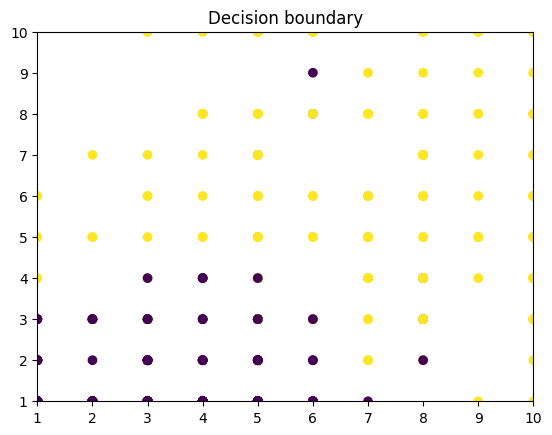

In [ ]:
X2 = X[:,0:2]
reg = LogisticRegression()
reg.fit(X2,y)

plt.scatter(X2[:,0],X2[:,1],c=y)

x_min, x_max = X2[:,0].min(), X2[:,0].max()
y_min, y_max = X2[:,1].min(), X2[:,1].max()

xx,yy = np.meshgrid(np.linspace(x_min,x_max,200),
                    np.linspace(y_min,y_max,200))

Z = reg.predict(np.c_[xx.ravel(),yy.ravel()])
Z = Z.reshape(xx.shape)

plt.contour(xx,yy,Z,levels=[0.5])
plt.title("Decision boundary")
plt.show()

In [ ]:
probs = reg.predict_proba(testX)[:,1]

plt.hist(probs,bins=20)
plt.title("Distribution of predicted probabilities")
plt.xlabel("P(malignant)")
plt.show()

NameError: name 'testX' is not defined